# 05 - Exploration et qualite des donnees : regarder le jeu avant d'entrainer (et surveiller la ligne apres)

La moitie des "bons resultats" faux vient des donnees, pas du modele. Ce notebook deroule, sans
etiquette ni entrainement :
1. les statistiques de chaque fichier : illisibles, tailles, types, canaux, images vides,
   saturees, floues ;
2. les doublons exacts et les quasi-doublons, en deux temps (empreinte dHash puis confirmation
   par la correlation des details) -> groupes -> decoupage groupe (sinon le test est truque) ;
3. les raccourcis : une statistique simple (luminosite, nettete, taille) qui predit la classe ;
4. les plongements d'un reseau pre-entraine : projection 2D, groupes, voisins ;
5. la derive de domaine entre deux periodes (classifieur de domaine + test de Kolmogorov-Smirnov).

Donnees : NEU-CLS, Magnetic Tile, NEU-DET (`python tools/get_data/get_neu_cls.py`,
`get_magnetic_tile.py`, `get_neu_det.py`). Prerequis : le socle de la toolbox pour `vtb.viz`.
Duree en mode QUICK sur un CPU 2 coeurs : 3 a 4 minutes. Lancer depuis la racine du depot.

**Dans le fil** : ce notebook approfondit l'etape 2 (Importer et explorer). Les groupes de
quasi-doublons servent a l'etape 4 (Decouper, par groupe) ; la derive se surveille en production,
apres l'etape 13 (Predire).
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

## 0. Reglages (etape 1)

Pour ses propres donnees : `CLASS_DIR` (un sous-dossier par classe) ou `MASK_DIR` (images +
masques), et les deux dossiers de la derive (`DRIFT_REFERENCE` = images d'entrainement,
`DRIFT_CURRENT` = images recentes de la ligne).

In [1]:
import hashlib  # hashlib : empreinte md5 d'un fichier (detecte les copies exactes)
import time  # time : chronometre (mesure des durees)
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture d'images, redimensionnement, filtres
import matplotlib.pyplot as plt  # matplotlib : histogrammes et nuages de points
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame) faciles a afficher, filtrer, regrouper
import torch  # PyTorch : tenseurs (tableaux de nombres sur CPU ou GPU) et reseaux de neurones (section 4)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from scipy.stats import ks_2samp  # test de Kolmogorov-Smirnov : deux echantillons suivent-ils la meme loi ? (section 5)
from sklearn.cluster import KMeans  # k-means : regroupe des vecteurs en k groupes, sans etiquette
from sklearn.decomposition import PCA  # PCA : projection lineaire qui garde le plus de variance (ici en 2D)
from sklearn.linear_model import LogisticRegression  # regression logistique : classifieur lineaire qui donne des probabilites
from sklearn.manifold import TSNE  # t-SNE : projection en 2D qui garde les voisinages locaux
from sklearn.metrics import roc_auc_score  # AUC : capacite a separer deux groupes (0,5 = hasard, 1 = parfait)
from sklearn.model_selection import (  # outils de decoupage du jeu et de validation croisee :
    StratifiedGroupKFold,  # plis stratifies qui gardent chaque groupe entier (doublons du meme cote)
    StratifiedKFold,  # plis qui gardent les proportions de classes
    cross_val_predict,  # prediction hors pli de chaque exemple
    cross_val_score,  # score moyen en validation croisee
    train_test_split,  # un seul decoupage train / test au hasard
)  # fin de la liste des outils de decoupage importes
from sklearn.pipeline import make_pipeline  # make_pipeline : enchaine des etapes (mise a l'echelle puis classifieur) en un seul modele
from sklearn.preprocessing import StandardScaler  # StandardScaler : met chaque variable a moyenne 0 et ecart-type 1
from sklearn.tree import DecisionTreeClassifier  # arbre de decision : suite de questions "valeur > seuil ?" (section 3)
from torchvision import models  # models : reseaux pre-entraines de torchvision (ici resnet18)

from vtb import viz  # viz : fonctions d'affichage de la toolbox (grilles d'images)

QUICK = True  # True : plongements sur 100 images par classe (rapide) ; False : tout le jeu
SEED = 0  # graine du hasard : memes tirages a chaque execution (resultats reproductibles)
CLASS_DIR = Path("data/raw/neu_cls_flat")  # NEU-CLS : un sous-dossier par classe
MASK_DIR = Path("data/raw/magnetic_tile")  # Magnetic Tile : MT_<type>/Imgs/x.jpg + masque x.png
MASK_EXTENSIONS = {".jpg"}  # seulement les .jpg : les .png du meme dossier sont les masques
DRIFT_REFERENCE = Path("data/raw/neu_det/IMAGES")  # derive : periode de reference (images d'entrainement)
DRIFT_CURRENT = Path("data/raw/neu_det/Validation_Images")  # derive : periode courante (meme acquisition ici)
DRIFT_MAX = 300  # images par cote : quelques centaines suffisent pour mesurer une derive
EMBED_PER_CLASS = 100 if QUICK else None  # images par classe pour les plongements : 100 en mode rapide, toutes sinon
MAX_HAMMING = 6  # candidats doublons : empreintes dHash differentes de 6 bits au plus (sur 64)
MIN_CORRELATION = 0.9  # confirmation d'un doublon : correlation des details >= 0,9
# calcule sur la carte graphique (GPU, "cuda") si elle existe, sinon sur le processeur (CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs/notebooks/05_exploration_qualite")  # dossier des fichiers ecrits par ce notebook
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier et ses parents ; pas d'erreur s'il existe deja
IMAGE_EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}  # extensions de fichiers reconnues comme images
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures a 80 points par pouce, en jpeg (notebook plus leger)


# renvoie les images d'un dossier (sous-dossiers compris), triees
def list_images(folder: Path, extensions: set[str] = IMAGE_EXTENSIONS) -> list[Path]:
    # rglob("*") parcourt tout ; garde les fichiers dont l'extension (en minuscules) est une image
    return sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in extensions)


# lit une image quelconque (8 ou 16 bits, gris ou couleur) ; renvoie un tableau numpy, couleur en RGB
def read_any(path: str | Path, flag: int = cv2.IMREAD_UNCHANGED) -> np.ndarray:
    """Lecture robuste (chemins Windows avec accents, 8 ou 16 bits) ; BGR remis en RGB."""
    # fromfile lit les octets (accents acceptes), imdecode decode ; IMREAD_UNCHANGED garde 8 ou 16 bits
    image = cv2.imdecode(np.fromfile(str(path), np.uint8), flag)
    if image is None:  # None = fichier illisible ou corrompu...
        raise ValueError(f"image illisible ou corrompue : {path}")  # ...on arrete avec un message clair
    if image.ndim == 3:  # image couleur (3 dimensions : hauteur, largeur, canaux)...
        # ...garde 3 canaux (retire la transparence) et passe de BGR (ordre OpenCV) a RGB
        image = cv2.cvtColor(image[..., :3], cv2.COLOR_BGR2RGB)
    return image  # renvoie l'image


def to_gray8(image: np.ndarray) -> np.ndarray:  # convertit une image en niveaux de gris 8 bits (0-255) et la renvoie
    gray = image if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)  # deja grise : gardee ; sinon conversion RGB -> gris
    # deja 8 bits : gardee ; sinon supposee 16 bits et ramenee de 0-65535 a 0-255 (arrondi)
    return gray if gray.dtype == np.uint8 else (gray.astype(np.float32) / 65535 * 255 + 0.5).astype(np.uint8)

## 1. Une ligne de statistiques par fichier (etape 2)

| colonne | ce qu'elle revele |
|---|---|
| readable / error | fichier tronque ou corrompu : il planterait l'entrainement au milieu de la nuit |
| height, width, channels, dtype | un uint16 parmi des uint8, une image RGB parmi des grises, des tailles melangees |
| mean, std | image noire (capot ferme), image uniforme, eclairage different entre deux periodes |
| saturated_fraction, dark_fraction | camera mal reglee, reflets |
| sharpness | variance du laplacien : faible = flou (mise au point, vibration) |
| md5, dhash | doublons exacts, quasi-doublons (section 3) |

Pour montrer un fichier illisible, on fabrique deux faux fichiers : un JPEG coupe en deux et un
fichier vide.

In [2]:
def dhash(gray8: np.ndarray, size: int = 8) -> int:  # empreinte perceptive 64 bits d'une image grise (dHash) ; renvoie un entier
    """Empreinte perceptive 64 bits : signe du gradient horizontal sur une vignette 9 x 8.

    Deux images presque identiques (recompression, luminosite un peu changee) ont des empreintes a
    quelques bits pres ; deux images differentes, a ~32 bits.
    """
    # vignette 9 x 8 (une colonne de plus pour 8 comparaisons par ligne), en entiers signes
    small = cv2.resize(gray8, (size + 1, size), interpolation=cv2.INTER_AREA).astype(np.int16)
    bits = (small[:, 1:] > small[:, :-1]).flatten()  # 64 booleens : chaque pixel est-il plus clair que son voisin de gauche ?
    return int(np.packbits(bits).view(">u8")[0])  # packbits range les 64 bits en 8 octets, lus comme un seul entier 64 bits


def image_stats(path: str | Path) -> dict:  # statistiques d'un fichier image ; renvoie un dict (une ligne du futur tableau)
    row: dict = {"path": str(path)}  # la ligne commence par le chemin
    try:  # on essaie de lire le fichier...
        data = Path(path).read_bytes()  # octets bruts (pour le md5)
        image = read_any(path)  # image decodee
    # ...si la lecture echoue, quelle qu'en soit la cause ("noqa" dit a ruff d'accepter ce except large)
    except Exception as error:  # noqa: BLE001 - on veut la cause, quelle qu'elle soit
        # ligne "illisible" avec le type et le message de l'erreur (120 caracteres au plus)
        return {**row, "readable": False, "error": f"{type(error).__name__}: {error}"[:120]}
    # valeur maximale possible selon le type : 255 (8 bits), 65535 (16 bits), 1.0 (decimal)
    peak = 255.0 if image.dtype == np.uint8 else 65535.0 if image.dtype == np.uint16 else 1.0
    gray = image if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)  # version grise de l'image
    values = gray.astype(np.float32) / peak  # valeurs ramenees dans [0, 1] pour comparer images 8 et 16 bits
    return {  # la ligne de statistiques :
        **row,  # le chemin
        "readable": True,  # fichier lisible
        "error": "",  # pas d'erreur
        "height": image.shape[0],  # hauteur en pixels
        "width": image.shape[1],  # largeur en pixels
        "channels": 1 if image.ndim == 2 else image.shape[2],  # nombre de canaux : 1 (gris) ou 3 (couleur)
        "dtype": str(image.dtype),  # type des pixels (uint8, uint16...)
        "mean": float(values.mean()),  # luminosite moyenne, dans [0, 1]
        "std": float(values.std()),  # ecart-type : contraste global (0 = image uniforme)
        "saturated_fraction": float((gray >= peak * 0.995).mean()),  # part des pixels satures (99,5 % du maximum ou plus)
        "dark_fraction": float((gray <= peak * 0.005).mean()),  # part des pixels quasi noirs
        # nettete : variance du laplacien (derivee seconde) ; faible = flou
        "sharpness": float(cv2.Laplacian(to_gray8(gray), cv2.CV_64F).var()),
        "md5": hashlib.md5(data).hexdigest(),  # empreinte md5 des octets : identique = copie exacte du fichier
        "dhash": dhash(to_gray8(gray)),  # empreinte perceptive (quasi-doublons)
    }


# statistiques numeriques etudiees dans la suite
STAT_COLUMNS = ["mean", "std", "height", "width", "sharpness", "saturated_fraction", "dark_fraction"]

neu = pd.DataFrame(  # catalogue NEU-CLS : une ligne (chemin, classe) par image
    # pour chaque sous-dossier de classe (trie) et chaque image qu'il contient
    [{"path": str(p), "label": d.name} for d in sorted(x for x in CLASS_DIR.iterdir() if x.is_dir()) for p in list_images(d)]
)
# catalogue Magnetic Tile : la classe est le 1er dossier du chemin (MT_<type>)
tiles = pd.DataFrame([{"path": str(p), "label": p.relative_to(MASK_DIR).parts[0]} for p in list_images(MASK_DIR, MASK_EXTENSIONS)])
broken_dir = OUT / "fichiers_casses"  # dossier des faux fichiers casses
broken_dir.mkdir(exist_ok=True)  # le cree s'il n'existe pas
source = Path(tiles["path"].iloc[0]).read_bytes()  # octets d'une vraie image de Magnetic Tile
(broken_dir / "coupe_en_deux.jpg").write_bytes(source[: len(source) // 8])  # JPEG tronque : seulement le premier huitieme du fichier
(broken_dir / "vide.png").write_bytes(b"")  # fichier vide (0 octet)

start = time.perf_counter()  # depart du chronometre
# statistiques de chaque image NEU-CLS, jointes au catalogue par le chemin
neu_stats = neu.merge(pd.DataFrame([image_stats(p) for p in neu["path"]]), on="path")
tile_stats = tiles.merge(pd.DataFrame([image_stats(p) for p in tiles["path"]]), on="path")  # idem pour Magnetic Tile
broken_stats = pd.DataFrame([image_stats(p) for p in sorted(broken_dir.iterdir())])  # statistiques des 2 fichiers casses
# nombre de fichiers lus et duree
print(f"{len(neu_stats) + len(tile_stats) + len(broken_stats)} fichiers lus en {time.perf_counter() - start:.0f} s")
display(broken_stats[["path", "readable", "error"]])  # les 2 fichiers casses doivent etre illisibles, avec leur cause

3146 fichiers lus en 3 s


,path,readable,error
0,outputs/notebooks/05_exploration_qualite/fichi...,False,ValueError: image illisible ou corrompue : out...
1,outputs/notebooks/05_exploration_qualite/fichi...,False,error: OpenCV(5.0.0) /io/opencv/modules/imgcod...


In [3]:
def overview(stats: pd.DataFrame, name: str) -> dict:  # resume d'un jeu (tailles, types, canaux, classes) ; renvoie un dict
    ok = stats[stats["readable"].astype(bool)]  # seulement les fichiers lisibles
    # nombre d'images par taille (hauteur, largeur), la plus frequente d'abord
    sizes = ok.groupby(["height", "width"]).size().sort_values(ascending=False)
    return {  # le resume :
        "jeu": name,  # nom du jeu
        "images": len(stats),  # nombre de fichiers
        "illisibles": int((~stats["readable"].astype(bool)).sum()),  # ~ inverse les booleens : compte les illisibles
        "types": dict(ok["dtype"].value_counts()),  # nombre d'images par type de pixel
        "canaux": dict(ok["channels"].value_counts()),  # nombre d'images par nombre de canaux
        "tailles differentes": len(sizes),  # nombre de tailles distinctes
        # "hauteur x largeur (nombre d'images)" de la taille la plus frequente
        "taille la plus frequente": f"{sizes.index[0][0]}x{sizes.index[0][1]} ({sizes.iloc[0]})",
        "classes": dict(ok["label"].value_counts().sort_index()),  # nombre d'images par classe
    }


# les deux resumes cote a cote (.T transpose : une colonne par jeu)
display(pd.DataFrame([overview(neu_stats, "NEU-CLS"), overview(tile_stats, "Magnetic Tile")]).set_index("jeu").T)

jeu,NEU-CLS,Magnetic Tile
images,1800,1344
illisibles,0,0
types,{'uint8': 1800},{'uint8': 1344}
canaux,{1: 1800},{1: 1344}
tailles differentes,1,1225
taille la plus frequente,200x200 (1800),375x265 (6)
classes,"{'crazing': 300, 'inclusion': 300, 'patches': ...","{'MT_Blowhole': 115, 'MT_Break': 85, 'MT_Crack..."


Magnetic Tile a presque autant de tailles d'image que d'images : un redimensionnement est
indispensable, et il faut se demander si la TAILLE ne trahit pas la classe (section 4).

### Images atypiques

Une statistique a plus de 4 ecarts robustes (MAD, insensible aux extremes) de la mediane de SA
classe, et les images vides ou saturees. On les regarde toujours : ce sont souvent des erreurs
d'acquisition, parfois les defauts les plus interessants.

NEU-CLS : 47 images atypiques | Magnetic Tile : 4


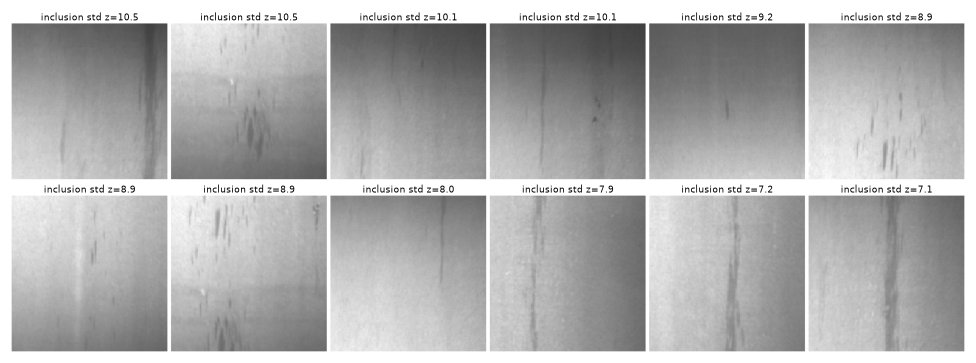

In [4]:
# repere les images atypiques ; renvoie un tableau (chemin, classe, statistique, z robuste)
def flag_outliers(stats: pd.DataFrame, z: float = 4.0) -> pd.DataFrame:
    ok = stats[stats["readable"].astype(bool)]  # seulement les fichiers lisibles
    flags = []  # morceaux de tableau a assembler
    for column in ("mean", "std", "sharpness"):  # pour 3 statistiques
        median = ok.groupby("label")[column].transform("median")  # mediane de SA classe, pour chaque image
        # MAD = mediane des ecarts a la mediane (robuste aux extremes) ; x 1,4826 : comparable a un ecart-type
        mad = ok.groupby("label")[column].transform(lambda s: (s - s.median()).abs().median()) * 1.4826
        # z robuste = nombre de MAD qui separent l'image de la mediane (MAD nul -> NaN : pas de division par 0)
        score = (ok[column] - median).abs() / mad.replace(0, np.nan)
        # images au-dela de z, avec la statistique en cause et leur score arrondi
        flags.append(ok.loc[score > z, ["path", "label"]].assign(statistique=column, z_robuste=score[score > z].round(1)))
    # images vides (contraste quasi nul), saturees (> 50 %) ou noires (> 90 %)
    empty = ok[(ok["std"] < 1e-3) | (ok["saturated_fraction"] > 0.5) | (ok["dark_fraction"] > 0.9)]
    flags.append(empty[["path", "label"]].assign(statistique="vide ou saturee", z_robuste=np.nan))  # ajoutees sans score (NaN)
    # assemble les morceaux, les plus atypiques d'abord
    return pd.concat(flags, ignore_index=True).sort_values("z_robuste", ascending=False)


outliers = flag_outliers(neu_stats)  # images atypiques de NEU-CLS
# nombre d'images atypiques de chaque jeu (une image peut l'etre pour plusieurs statistiques)
print(f"NEU-CLS : {outliers['path'].nunique()} images atypiques | Magnetic Tile : {flag_outliers(tile_stats)['path'].nunique()}")
top = outliers.drop_duplicates("path").head(12)  # les 12 plus atypiques, chaque image une seule fois
viz.grid(  # grille des images atypiques :
    top["path"].tolist(),  # chemins des images (viz.grid sait les lire)
    [f"{lab} {s} z={z}" for lab, s, z in zip(top["label"], top["statistique"], top["z_robuste"])],  # titres : classe, statistique, z
    ncols=6,  # 6 colonnes
    size=2.0,  # taille des vignettes (pouces)
)

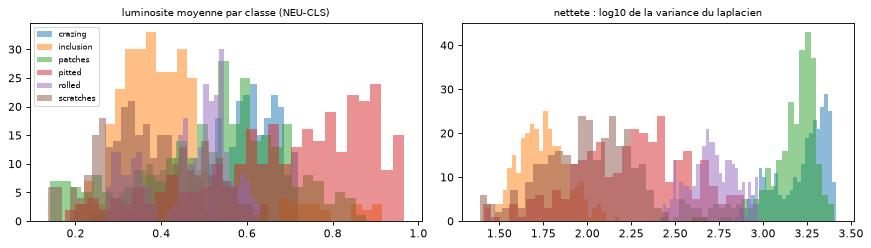

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))  # figure de 2 graphiques cote a cote
for label, group in neu_stats.groupby("label"):  # pour chaque classe et ses lignes
    axes[0].hist(group["mean"], bins=30, alpha=0.5, label=label)  # histogramme des luminosites moyennes (alpha = transparence)
    # histogramme de la nettete en echelle log (+1 evite log(0))
    axes[1].hist(np.log10(group["sharpness"] + 1), bins=30, alpha=0.5, label=label)
axes[0].set_title("luminosite moyenne par classe (NEU-CLS)", fontsize=9)  # titre du 1er graphique
axes[1].set_title("nettete : log10 de la variance du laplacien", fontsize=9)  # titre du 2e graphique
axes[0].legend(fontsize=7)  # legende des classes
plt.tight_layout()  # resserre la mise en page
plt.show()  # affiche la figure

## 2. Doublons et quasi-doublons (etapes 2 et 4)

Un doublon dans deux sous-ensembles (train et test) truque le test : le modele a deja vu
l'image. Deux copies avec deux etiquettes differentes sont une erreur d'annotation.

Recherche en deux temps, pour rester rapide sans crier au loup :
1. candidats : empreintes dHash a <= `MAX_HAMMING` bits ; toutes les paires sont comparees par
   XOR et comptage de bits (1,6 million de paires en une fraction de seconde) ;
2. confirmation : correlation des DETAILS de deux vignettes 64 x 64 dont on a retire les basses
   frequences. Sur une surface d'acier, dHash ne voit que l'eclairage commun : sans cette etape,
   des milliers de paires d'images differentes seraient declarees doublons.

In [6]:
# signature des details d'une image ; renvoie un vecteur norme de 64 x 64 valeurs
def detail_signature(path: str, size: int = 64) -> np.ndarray:
    """Vignette sans ses basses frequences, centree et normee : le "detail" propre a l'image."""
    # vignette 64 x 64 en gris, en nombres decimaux
    small = cv2.resize(to_gray8(read_any(path)), (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)
    detail = small - cv2.GaussianBlur(small, (0, 0), 3)  # retire le flou (basses frequences = eclairage) : il reste les details
    detail -= detail.mean()  # centre a moyenne 0
    # divise par la norme (1e-6 evite la division par 0) et met a plat : produit scalaire = correlation
    return (detail / max(float(np.linalg.norm(detail)), 1e-6)).ravel()


def find_duplicates(  # cherche doublons et quasi-doublons ; renvoie (paires confirmees, nombre de candidats)
    stats: pd.DataFrame,  # tableau de image_stats
    max_hamming: int = MAX_HAMMING,  # seuil de distance dHash des candidats
    min_correlation: float = MIN_CORRELATION,  # seuil de correlation pour confirmer
) -> tuple[pd.DataFrame, int]:  # renvoie un tableau et un entier
    """(paires confirmees, nombre de candidats dHash). Colonnes label_conflict / cross_split : les deux cas graves."""
    ok = stats[stats["readable"].astype(bool)].reset_index(drop=True)  # fichiers lisibles, renumerotes 0, 1, 2...
    hashes, md5 = ok["dhash"].astype("uint64").to_numpy(), ok["md5"].to_numpy()  # empreintes dHash en entiers 64 bits non signes, et md5
    candidates = []  # paires (i, j, distance) proches en dHash
    for i in range(len(ok) - 1):  # pour chaque image i...
        # ...distance de Hamming (bits differents : XOR puis comptage) avec toutes les images suivantes
        distances = np.bitwise_count(hashes[i] ^ hashes[i + 1 :])
        # garde les paires a max_hamming bits au plus
        candidates.extend((i, i + 1 + int(o), int(distances[o])) for o in np.flatnonzero(distances <= max_hamming))
    signatures: dict[int, np.ndarray] = {}  # cache : signature de detail deja calculee pour chaque image
    rows = []  # lignes du resultat
    for i, j, distance in candidates:  # pour chaque paire candidate
        exact = md5[i] == md5[j]  # meme md5 = copie exacte
        if not exact:  # sinon il faut confirmer :
            for k in (i, j):  # pour les deux images
                if k not in signatures:  # signature pas encore calculee...
                    signatures[k] = detail_signature(ok["path"].iloc[k])  # ...on la calcule une seule fois
            correlation = float(signatures[i] @ signatures[j])  # @ = produit scalaire de vecteurs normes = correlation des details
            if correlation < min_correlation:  # details trop differents...
                continue  # ...pas un doublon : paire suivante
        a, b = ok.iloc[i], ok.iloc[j]  # les deux lignes de statistiques
        row = {  # ligne du resultat :
            "path_a": a["path"],  # chemin de la 1re image
            "path_b": b["path"],  # chemin de la 2e image
            "hamming": distance,  # distance dHash
            "correlation": 1.0 if exact else round(correlation, 4),  # 1 pour une copie exacte
            "exact": bool(exact),  # copie exacte ?
        }
        # classes des deux images ; conflit = meme image avec deux classes (erreur d'annotation)
        row.update({"label_a": a["label"], "label_b": b["label"], "label_conflict": a["label"] != b["label"]})
        if "split" in ok:  # si le tableau dit a quel sous-ensemble (train, test...) appartient chaque image...
            row["cross_split"] = a["split"] != b["split"]  # ...doublon a cheval sur deux sous-ensembles = test truque
        rows.append(row)  # garde la paire
    return pd.DataFrame(rows), len(candidates)  # paires confirmees et nombre de candidats


# regroupe les images liees par des paires (union-find) ; renvoie un tableau (chemin, groupe)
def duplicate_groups(paths: list[str], pairs: pd.DataFrame) -> pd.DataFrame:
    """Union-find : composantes connexes du graphe des paires -> une colonne group (dup_0000... ou le chemin seul)."""
    parent = {p: p for p in paths}  # union-find : au depart, chaque image est son propre chef de groupe

    def root(p: str) -> str:  # renvoie le chef du groupe de p
        while parent[p] != p:  # tant qu'on n'est pas au chef...
            parent[p] = parent[parent[p]]  # ...raccourcit le chemin (saute un niveau)
            p = parent[p]  # et monte d'un cran
        return p  # le chef du groupe

    for a, b in zip(pairs.get("path_a", []), pairs.get("path_b", [])):  # pour chaque paire de doublons (aucune si le tableau est vide)
        parent[root(a)] = root(b)  # fusionne les groupes des deux images
    roots = {p: root(p) for p in paths}  # chef de groupe de chaque image
    sizes = pd.Series(list(roots.values())).value_counts()  # taille de chaque groupe
    # nom dup_0000, dup_0001... pour chaque groupe d'au moins 2 images
    names = {r: f"dup_{k:04d}" for k, r in enumerate(sizes[sizes > 1].index)}
    # une image seule a pour groupe son propre chemin
    return pd.DataFrame({"path": paths, "group": [names.get(roots[p], p) for p in paths]})


rows = []  # lignes du tableau
for name, stats in (("NEU-CLS", neu_stats), ("Magnetic Tile", tile_stats)):  # pour chacun des deux jeux
    start = time.perf_counter()  # depart du chronometre
    pairs, n_candidates = find_duplicates(stats)  # cherche les doublons
    rows.append(  # ligne du tableau :
        {  # dictionnaire de la ligne
            "jeu": name,  # nom du jeu
            "candidats dHash": n_candidates,  # paires candidates (dHash proche)
            "paires confirmees": len(pairs),  # paires confirmees par la correlation
            "copies exactes": int(pairs["exact"].sum()) if len(pairs) else 0,  # dont copies exactes (0 si aucune paire)
            # paires dont les deux images ont des classes differentes
            "paires a deux etiquettes": int(pairs["label_conflict"].sum()) if len(pairs) else 0,
            "secondes": round(time.perf_counter() - start, 1),  # duree de la recherche
        }
    )
    if name == "Magnetic Tile":  # garde les paires de Magnetic Tile pour la suite
        tile_pairs = pairs  # (paires de quasi-doublons de Magnetic Tile)
display(pd.DataFrame(rows).set_index("jeu"))  # affiche le tableau

groups = duplicate_groups(tile_stats["path"].tolist(), tile_pairs)  # groupes de quasi-doublons de Magnetic Tile
groups.to_csv(OUT / "groups.csv", index=False)  # sauvegarde ; a donner a data.groups_csv avec split.strategy: grouped
in_groups = groups[groups["group"].str.startswith("dup_")]  # images qui sont dans un vrai groupe (dup_...)
# nombre d'images, de groupes, et chemin du fichier ecrit
print(f"Magnetic Tile : {len(in_groups)} images dans {in_groups['group'].nunique()} groupes de quasi-doublons -> {OUT / 'groups.csv'}")

,candidats dHash,paires confirmees,copies exactes,paires a deux etiquettes,secondes
jeu,,,,,
NEU-CLS,9724,2,1,0,0.1
Magnetic Tile,14348,301,0,4,1.1


Magnetic Tile : 418 images dans 161 groupes de quasi-doublons -> outputs/notebooks/05_exploration_qualite/groups.csv


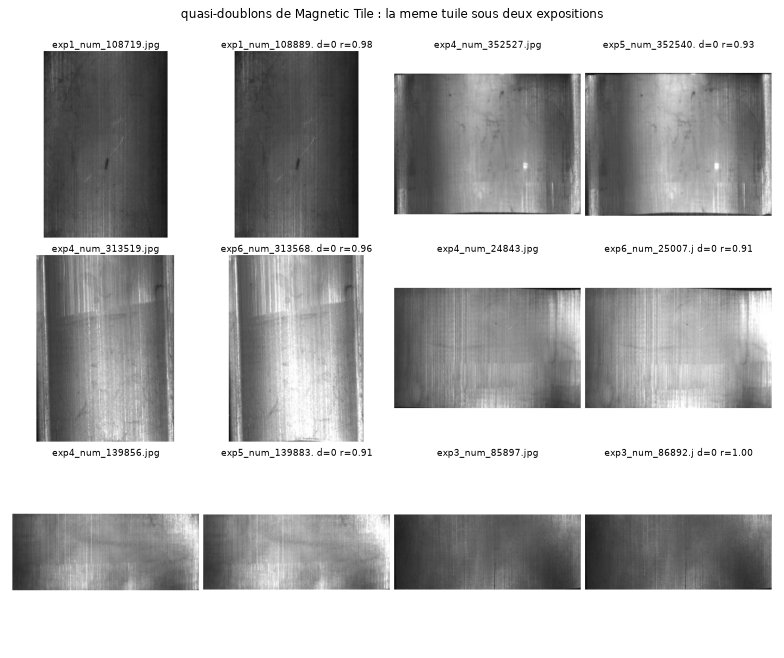

In [7]:
shown = tile_pairs.sort_values("hamming").drop_duplicates("path_a").head(6)  # 6 paires parmi les plus proches, une par image de depart
images, titles = [], []  # vignettes et titres
for _, pair in shown.iterrows():  # pour chaque paire (iterrows donne (indice, ligne))
    images += [pair["path_a"], pair["path_b"]]  # les deux images cote a cote
    # nom de la 1re ; nom de la 2e avec distance dHash d et correlation r
    titles += [Path(pair["path_a"]).name[:24], f"{Path(pair['path_b']).name[:16]} d={pair['hamming']} r={pair['correlation']:.2f}"]
# 4 colonnes : 2 paires par ligne
viz.grid(images, titles, ncols=4, size=2.4, suptitle="quasi-doublons de Magnetic Tile : la meme tuile sous deux expositions")

### La fuite, mesuree

Magnetic Tile contient la meme tuile photographiee sous plusieurs expositions (`exp1` a `exp6`).
Avec un decoupage aleatoire, des copies d'une tuile tombent dans train ET test ; avec un
decoupage GROUPE (StratifiedGroupKFold sur les groupes ci-dessus), jamais.

In [8]:
frame = tile_stats[["path", "label"]].merge(groups, on="path")  # chemin, classe et groupe de chaque tuile
# decoupage ALEATOIRE stratifie (proportions de classes gardees) : 20 % en test
_, test_random = train_test_split(frame.index, test_size=0.2, stratify=frame["label"], random_state=SEED)
# decoupage GROUPE en 5 plis : un groupe n'est jamais coupe entre train et test
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
_, test_grouped = next(folds.split(frame, frame["label"], groups=frame["group"]))  # 1er pli comme test (20 % des images)
leaks = {}  # resultats par decoupage
for name, test_index in (("aleatoire stratifie", test_random), ("groupe", frame.index[test_grouped])):  # pour les 2 decoupages
    in_test = set(frame.loc[test_index, "path"])  # chemins des images de test
    # paires dont une image est en test et l'autre en train : une fuite
    crossing = sum((a in in_test) != (b in in_test) for a, b in zip(tile_pairs["path_a"], tile_pairs["path_b"]))
    leaks[name] = {"images de test": len(in_test), "paires de doublons a cheval train / test": crossing}  # resultat du decoupage
display(pd.DataFrame(leaks).T)  # affiche le tableau

,images de test,paires de doublons a cheval train / test
aleatoire stratifie,269,89
groupe,269,0


## 3. Raccourcis : une statistique simple predit-elle la classe ? (etape 2)

Pour chaque statistique, un petit arbre (profondeur 3) predit la classe avec elle SEULE ;
exactitude equilibree en validation croisee. Proche du hasard (1 / nombre de classes) : normal.
Tres au-dessus : la classe se lit dans la luminosite, la taille ou la nettete (classes prises sur
des lignes, des cameras ou a des heures differentes) et le modele apprendra CA, pas le defaut.
Regle d'alerte : une statistique seule fait plus de 60 % du chemin entre le hasard et la perfection.

In [9]:
# pour chaque statistique : un arbre la seule predit-il la classe ? renvoie un tableau
def shortcut_scores(stats: pd.DataFrame, seed: int = SEED) -> pd.DataFrame:
    ok = stats[stats["readable"].astype(bool)]  # seulement les fichiers lisibles
    labels = ok["label"].astype(str)  # classes en texte
    folds = min(5, int(labels.value_counts().min()))  # 5 plis, ou moins si une classe a moins de 5 images
    rows = []  # lignes du tableau
    for column in STAT_COLUMNS:  # pour chaque statistique
        x = ok[[column]].to_numpy(dtype=float)  # une seule colonne : tableau (images, 1)
        if np.nanstd(x) == 0:  # statistique constante (une seule taille par exemple)...
            continue  # ...rien a apprendre
        tree = DecisionTreeClassifier(max_depth=3, random_state=seed)  # petit arbre de decision, 3 questions au plus
        rows.append(  # ligne du tableau :
            {  # dictionnaire de la ligne
                "statistique": column,  # nom de la statistique
                # exactitude equilibree (moyenne des rappels par classe), moyenne des plis de la validation croisee
                "exactitude equilibree": round(float(cross_val_score(tree, x, labels, cv=folds, scoring="balanced_accuracy").mean()), 3),
            }
        )
    # tableau trie, meilleure statistique en tete
    table = pd.DataFrame(rows).sort_values("exactitude equilibree", ascending=False).reset_index(drop=True)
    chance = 1 / labels.nunique()  # score du hasard : 1 / nombre de classes
    table["hasard"] = round(chance, 3)  # colonne de reference
    # alerte : plus de 60 % du chemin entre hasard et perfection
    table["alerte"] = table["exactitude equilibree"] > chance + 0.6 * (1 - chance)
    return table  # renvoie le tableau


# Cas plante : chaque classe photographiee un jour different, avec une exposition propre a ce jour
# (luminosite moyenne fixee par le jour, a un petit bruit pres). Simulation sur la table des statistiques.
planted = neu_stats.copy()  # copie des statistiques NEU-CLS a truquer
# chaque classe recoit une luminosite propre : 0,30, 0,38, 0,46...
day_exposure = planted["label"].map({c: 0.3 + 0.08 * k for k, c in enumerate(sorted(planted["label"].unique()))})
planted["mean"] = day_exposure + np.random.default_rng(SEED).normal(0, 0.015, len(planted))  # + petit bruit (ecart-type 0,015)
# pour les 2 jeux reels et le cas plante
for name, stats in (("NEU-CLS", neu_stats), ("Magnetic Tile", tile_stats), ("NEU-CLS, exposition differente par classe (plante)", planted)):
    print(name)  # nom du jeu
    display(shortcut_scores(stats).head(4))  # les 4 statistiques les plus predictives

NEU-CLS


,statistique,exactitude equilibree,hasard,alerte
0,sharpness,0.585,0.167,False
1,std,0.506,0.167,False
2,mean,0.404,0.167,False
3,saturated_fraction,0.352,0.167,False


Magnetic Tile


,statistique,exactitude equilibree,hasard,alerte
0,height,0.222,0.167,False
1,width,0.192,0.167,False
2,mean,0.177,0.167,False
3,std,0.167,0.167,False


NEU-CLS, exposition differente par classe (plante)


,statistique,exactitude equilibree,hasard,alerte
0,mean,0.889,0.167,True
1,sharpness,0.585,0.167,False
2,std,0.506,0.167,False
3,saturated_fraction,0.352,0.167,False


Lecture : sur NEU-CLS, la nettete seule predit la classe bien au-dela du hasard sans declencher
l'alerte : c'est attendu, les classes different par leur texture. Le cas plante declenche
l'alerte sur `mean` : avant d'accuser (ou de feliciter) le modele, verifier l'acquisition.
Sur Magnetic Tile, aucune statistique ne trahit la classe : la taille d'image, pourtant tres
variable, reste proche du hasard (a verifier sur chaque nouveau jeu).

## 4. Plongements : un vecteur par image, sans etiquette (etape 2)

Un reseau pre-entraine (resnet18 ImageNet) sans sa tete donne un vecteur de 512 valeurs par
image ; normalise, le produit scalaire de deux vecteurs est leur similarite cosinus. A quoi ca
sert sans aucune etiquette : voir la structure du jeu (les classes se separent-elles ? deux
cameras ?), regrouper pour annoter plus vite, chercher les voisins d'une image, mesurer une derive.

600 plongements de dimension 512 en 15 s


k-means a 6 groupes : purete 0.903 (part des images dont l'etiquette est la majoritaire de leur groupe)


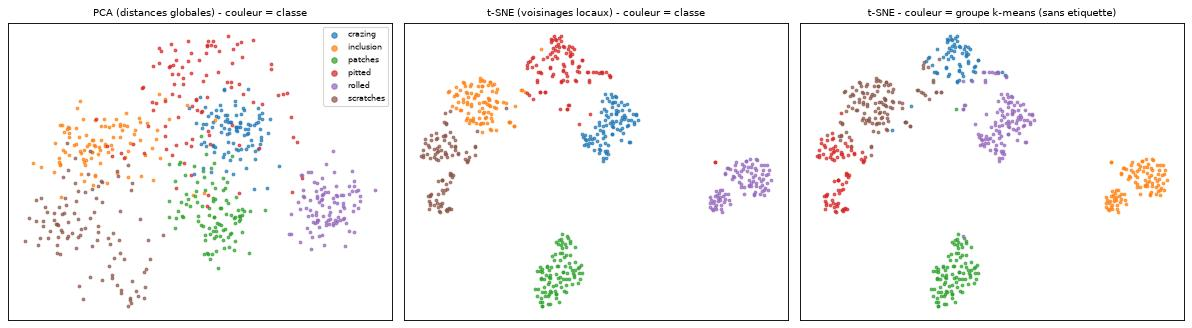

In [10]:
backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)  # resnet18 pre-entraine sur ImageNet (1,2 million de photos)
backbone.fc = torch.nn.Identity()  # retire la tete de classification : la sortie devient le vecteur de 512 valeurs du pooling global
backbone = backbone.eval().to(DEVICE)  # mode evaluation (BatchNorm fige), sur GPU ou CPU
# moyenne ImageNet par canal (R, V, B), forme (1, 3, 1, 1) pour s'appliquer a tout un lot
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)  # ecart-type ImageNet par canal


@torch.no_grad()  # decorateur : aucun gradient (direction de correction des poids) n'est calcule, on ne fait que predire
# plongements (vecteurs normes de 512 valeurs) d'une liste d'images ; renvoie un tableau (N, 512)
def embed(paths: list[str], batch_size: int = 64) -> np.ndarray:
    out = []  # morceaux du resultat
    for start in range(0, len(paths), batch_size):  # par lots de batch_size images (lot = paquet traite d'un coup)
        # lit les images du lot en gris et les redimensionne a 224 x 224 (taille d'entree du resnet)
        batch = [cv2.resize(to_gray8(read_any(p)), (224, 224), interpolation=cv2.INTER_AREA) for p in paths[start : start + batch_size]]
        # tenseur (lot, 1, 224, 224) dans [0, 1], canal gris repete 3 fois (le reseau attend du RGB)
        x = torch.from_numpy(np.stack(batch)).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
        # normalisation ImageNet puis passage dans le reseau : (lot, 512)
        features = backbone(((x - IMAGENET_MEAN) / IMAGENET_STD).to(DEVICE))
        # norme 1 par vecteur (produit scalaire = similarite cosinus), retour en numpy
        out.append(torch.nn.functional.normalize(features, dim=1).cpu().numpy())
    return np.concatenate(out)  # tous les lots en un seul tableau


# echantillon : EMBED_PER_CLASS images par classe (graine fixe), ou tout le jeu
sample = neu if EMBED_PER_CLASS is None else neu.groupby("label", group_keys=False).sample(n=EMBED_PER_CLASS, random_state=SEED)
sample = sample.reset_index(drop=True)  # renumerote les lignes 0, 1, 2...
start = time.perf_counter()  # depart du chronometre
vectors = embed(sample["path"].tolist())  # un vecteur par image
print(f"{len(vectors)} plongements de dimension {vectors.shape[1]} en {time.perf_counter() - start:.0f} s")  # nombre, dimension, duree
xy_pca = PCA(n_components=2, random_state=SEED).fit_transform(vectors)  # PCA : projection lineaire en 2D (distances globales)
xy_tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(  # t-SNE en 2D (voisinages locaux)...
    PCA(n_components=50, random_state=SEED).fit_transform(vectors)  # ...apres une PCA a 50 dimensions (plus rapide, moins de bruit)
)
# k-means : autant de groupes que de classes, 10 essais, sans etiquette
clusters = KMeans(n_clusters=sample["label"].nunique(), n_init=10, random_state=SEED).fit_predict(vectors)
# purete : part des images dont la classe est la majoritaire de leur groupe
purity = sum(pd.Series(sample["label"][clusters == c]).value_counts().iloc[0] for c in np.unique(clusters)) / len(sample)
print(  # affiche la purete :
    # texte affiche
    f"k-means a {sample['label'].nunique()} groupes : purete {purity:.3f} (part des images dont l'etiquette est la majoritaire de leur groupe)"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))  # figure de 3 graphiques
# pour la PCA puis le t-SNE (axe, coordonnees, titre)
for ax, xy, title in ((axes[0], xy_pca, "PCA (distances globales)"), (axes[1], xy_tsne, "t-SNE (voisinages locaux)")):
    for label in sorted(sample["label"].unique()):  # pour chaque classe
        m = (sample["label"] == label).to_numpy()  # masque : images de cette classe
        ax.scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.7, label=label)  # nuage de points de la classe (s = taille des points)
    ax.set_title(f"{title} - couleur = classe", fontsize=9)  # titre du graphique
    ax.set_xticks([])  # pas de graduations : ces axes n'ont pas de sens physique
    ax.set_yticks([])  # idem en vertical
axes[0].legend(fontsize=7, markerscale=2)  # legende (markerscale grossit les points)
for c in np.unique(clusters):  # pour chaque groupe k-means
    m = clusters == c  # masque : images de ce groupe
    axes[2].scatter(xy_tsne[m, 0], xy_tsne[m, 1], s=6, alpha=0.7, label=f"groupe {c}")  # ses points sur le t-SNE
axes[2].set_title("t-SNE - couleur = groupe k-means (sans etiquette)", fontsize=9)  # titre du 3e graphique
axes[2].set_xticks([])  # pas de graduations
axes[2].set_yticks([])  # idem en vertical
plt.tight_layout()  # resserre la mise en page
plt.show()  # affiche la figure

Voisins : pour une image de chaque classe, les 5 images les plus proches (similarite cosinus).
C'est l'outil pour retrouver "toutes les images qui ressemblent a ce defaut" dans un stock non trie.

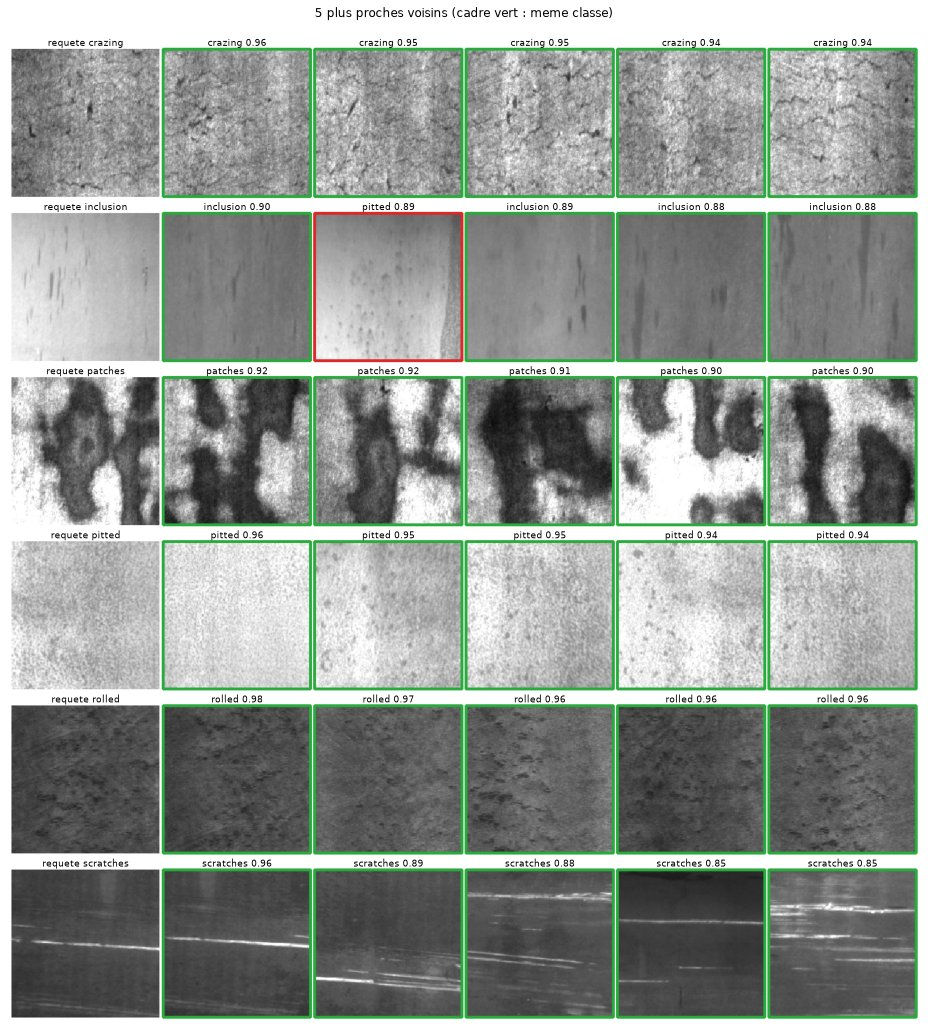

In [11]:
# indice de la 1re image de chaque classe : les images requetes
queries = [int(sample.index[sample["label"] == label][0]) for label in sorted(sample["label"].unique())]
sims = vectors[queries] @ vectors.T  # similarite cosinus de chaque requete avec toutes les images (vecteurs normes)
order = np.argsort(-sims, axis=1)[:, :6]  # indices des 6 plus similaires ; la 1re est la requete elle-meme (similarite 1)
images, titles, borders = [], [], []  # vignettes, titres, cadres
for q, row in zip(queries, order):  # pour chaque requete et ses voisins
    for rank, j in enumerate(row):  # pour chaque voisin, avec son rang (0 = la requete)
        images.append(sample["path"].iloc[j])  # chemin de l'image
        titles.append(  # titre :
            # "requete classe" pour la requete, sinon "classe similarite"
            f"requete {sample['label'].iloc[q]}" if rank == 0 else f"{sample['label'].iloc[j][:9]} {sims[queries.index(q), j]:.2f}"
        )
        # pas de cadre pour la requete ; sinon vert si meme classe, rouge sinon
        borders.append(None if rank == 0 else sample["label"].iloc[j] == sample["label"].iloc[q])
# une ligne par requete : la requete puis ses 5 voisins
viz.grid(images, titles, ncols=6, size=1.9, borders=borders, suptitle="5 plus proches voisins (cadre vert : meme classe)")

## 5. Derive de domaine : les images d'aujourd'hui ressemblent-elles a celles de l'entrainement ? (apres l'etape 13)

Changement de camera, d'eclairage, de nuance d'acier, objectif sale : le modele ne previent pas,
il se trompe en silence. Deux mesures complementaires, sans etiquette :
1. classifieur de domaine : une regression logistique essaie de distinguer "reference" et
   "courant" a partir des plongements. AUC ~ 0,5 : indiscernables ; AUC proche de 1 : derive.
   C'est le test le plus sensible, et il dit QUELLES images sont les plus nouvelles ;
2. statistiques simples, test de Kolmogorov-Smirnov colonne par colonne : moins sensible, mais il
   dit QUOI a change (plus sombre, plus flou...).

Deux essais : le dossier de validation livre a part avec NEU-DET (meme acquisition : pas de derive
attendue), puis une derive SIMULEE (images assombries par un gamma 1,4 et legerement floues :
eclairage qui vieillit, objectif encrasse), ecrite sur disque pour tout relire comme en vrai.

,images ref / courant,AUC domaine,verdict,statistique la plus changee
courant,,,,
validation livree a part,300 / 30,0.392,pas de derive detectable,"mean (KS 0.187, 0.4659 -> 0.5075)"
"derive simulee (gamma 1,4 + flou 1,2)",300 / 150,0.996,derive forte : reevaluer le modele,"sharpness (KS 0.717, 374.0855 -> 13.121)"


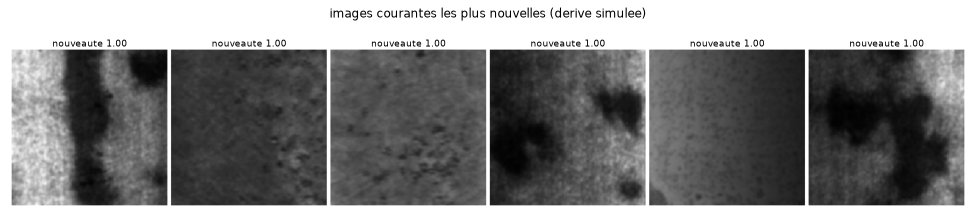

In [12]:
# classifieur de domaine : distingue reference et courant ; renvoie (AUC, probabilite "courant" des images courantes)
def domain_classifier(reference: np.ndarray, current: np.ndarray, seed: int = SEED) -> tuple[float, np.ndarray]:
    """AUC en validation croisee (5 plis) et probabilite "courant" de chaque image courante (hors pli)."""
    x = np.concatenate([reference, current])  # tous les vecteurs, reference puis courant
    y = np.r_[np.zeros(len(reference)), np.ones(len(current))]  # etiquette de domaine : 0 = reference, 1 = courant
    # 5 plis stratifies (moins si un cote a moins de 5 images)
    folds = StratifiedKFold(n_splits=min(5, len(reference), len(current)), shuffle=True, random_state=seed)
    # standardisation puis regression logistique ; C = 0,1 : forte regularisation
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    # probabilite "courant" hors pli de chaque image ([:, 1] = 2e colonne)
    proba = cross_val_predict(model, x, y, cv=folds, method="predict_proba")[:, 1]
    return float(roc_auc_score(y, proba)), proba[len(reference) :]  # AUC (0,5 = indiscernables) ; probabilites des seules images courantes


# test de Kolmogorov-Smirnov par statistique ; renvoie un tableau, la plus changee d'abord
def statistics_drift(reference: pd.DataFrame, current: pd.DataFrame) -> pd.DataFrame:
    rows = []  # lignes du tableau
    for column in STAT_COLUMNS:  # pour chaque statistique
        a, b = reference[column].to_numpy(float), current[column].to_numpy(float)  # valeurs de la statistique dans les deux periodes
        test = ks_2samp(a, b)  # KS : ecart maximal entre les deux distributions cumulees
        rows.append(  # ligne du tableau :
            {  # dictionnaire de la ligne
                "statistique": column,  # nom de la statistique
                "ks": round(float(test.statistic), 3),  # 0 = memes distributions, 1 = completement separees
                "p": float(test.pvalue),  # p-valeur : petite = difference peu probable par hasard
                "mediane ref": round(float(np.median(a)), 4),  # mediane de la reference
                "mediane courant": round(float(np.median(b)), 4),  # mediane de la periode courante
            }
        )
    return pd.DataFrame(rows).sort_values("ks", ascending=False).reset_index(drop=True)  # trie par KS decroissant


def verdict(auc: float) -> str:  # traduit l'AUC en phrase
    return (  # selon l'AUC :
        # < 0,6 : rien ; < 0,75 : moderee ; sinon : forte
        "pas de derive detectable" if auc < 0.6 else "derive moderee : surveiller" if auc < 0.75 else "derive forte : reevaluer le modele"
    )


def gamma_lut(image: np.ndarray, gamma: float) -> np.ndarray:  # applique une correction gamma a une image 8 bits ; renvoie l'image
    levels = np.arange(256, dtype=np.float64) / 255  # les 256 niveaux ramenes dans [0, 1]
    # LUT = table de correspondance niveau -> niveau^gamma (gamma > 1 assombrit)
    return cv2.LUT(image, np.round(levels**gamma * 255).astype(np.uint8))


# reference : 300 images de NEU-DET tirees au hasard (graine fixe), triees
reference_paths = pd.Series([str(p) for p in list_images(DRIFT_REFERENCE)]).sample(n=DRIFT_MAX, random_state=SEED).sort_values().tolist()
current_paths = [str(p) for p in list_images(DRIFT_CURRENT)][:DRIFT_MAX]  # courant : les images du dossier de validation (300 au plus)
simulated_dir = OUT / "derive_simulee"  # dossier des images a derive simulee
simulated_dir.mkdir(exist_ok=True)  # le cree s'il n'existe pas
simulated_paths = []  # chemins des images simulees
# 150 autres images de reference (autre graine), numerotees
for k, p in enumerate(pd.Series([str(p) for p in list_images(DRIFT_REFERENCE)]).sample(n=150, random_state=SEED + 1)):
    # gamma 1,4 (plus sombre) puis flou gaussien de 1,2 pixel (bords en miroir)
    altered = cv2.GaussianBlur(gamma_lut(to_gray8(read_any(p)), 1.4), (0, 0), 1.2, borderType=cv2.BORDER_REFLECT)
    target = simulated_dir / f"{k:05d}_{Path(p).stem}.png"  # nom du fichier : numero + nom d'origine, en PNG
    cv2.imencode(".png", altered)[1].tofile(str(target))  # ecrit le PNG (imencode + tofile : chemins avec accents acceptes)
    simulated_paths.append(str(target))  # garde le chemin

ref_vectors = embed(reference_paths)  # plongements de la reference
ref_stats = pd.DataFrame([image_stats(p) for p in reference_paths])  # statistiques de la reference
drift_rows, novelty = [], {}  # lignes du tableau ; images classees par nouveaute
# pour les 2 periodes courantes : validation livree a part, derive simulee
for name, paths in (("validation livree a part", current_paths), ("derive simulee (gamma 1,4 + flou 1,2)", simulated_paths)):
    auc, proba = domain_classifier(ref_vectors, embed(paths))  # classifieur de domaine reference / courant
    changed = statistics_drift(ref_stats, pd.DataFrame([image_stats(p) for p in paths]))  # test KS sur chaque statistique
    # images courantes triees par probabilite "courant" (les plus nouvelles d'abord)
    novelty[name] = pd.DataFrame({"path": paths, "nouveaute": proba}).sort_values("nouveaute", ascending=False)
    drift_rows.append(  # ligne du tableau :
        {  # dictionnaire de la ligne
            "courant": name,  # nom de la periode courante
            "images ref / courant": f"{len(reference_paths)} / {len(paths)}",  # nombres d'images
            "AUC domaine": round(auc, 3),  # AUC du classifieur de domaine
            "verdict": verdict(auc),  # verdict en clair
            # la statistique au plus grand KS, avec sa mediane avant -> apres
            "statistique la plus changee": f"{changed['statistique'][0]} (KS {changed['ks'][0]}, {changed['mediane ref'][0]} -> {changed['mediane courant'][0]})",
        }
    )
drift_table = pd.DataFrame(drift_rows).set_index("courant")  # tableau indexe par periode
display(drift_table)  # affiche le tableau
top = novelty["derive simulee (gamma 1,4 + flou 1,2)"].head(6)  # les 6 images simulees les plus nouvelles
viz.grid(  # grille :
    top["path"].tolist(),  # les images
    [f"nouveaute {v:.2f}" for v in top["nouveaute"]],  # titres : probabilite "courant"
    ncols=6,  # 6 colonnes
    size=2.0,  # taille des vignettes (pouces)
    suptitle="images courantes les plus nouvelles (derive simulee)",  # titre general
)

Peu d'images courantes (30 pour le dossier de validation) rendent l'AUC bruitee : quelques
centaines par cote suffisent. En surveillance de ligne : reference = le dossier d'entrainement,
courant = les images de la derniere semaine ; regarder les images les plus nouvelles des que
l'AUC depasse 0,6.

## 6. Resultats

In [13]:
results = {  # chiffres cles du notebook :
    "fichiers illisibles detectes (2 fabriques)": int((~broken_stats["readable"].astype(bool)).sum()),  # doit valoir 2
    "NEU-CLS : paires de doublons confirmees": int(rows[0]["paires confirmees"]),  # section 2
    "Magnetic Tile : paires confirmees": int(rows[1]["paires confirmees"]),  # section 2
    "Magnetic Tile : images en groupes / groupes": f"{len(in_groups)} / {in_groups['group'].nunique()}",  # section 2
    # paires a cheval train / test : decoupage aleatoire puis groupe (0 attendu)
    "fuite (paires a cheval) decoupage aleatoire / groupe": f"{leaks['aleatoire stratifie']['paires de doublons a cheval train / test']} / {leaks['groupe']['paires de doublons a cheval train / test']}",
    "purete k-means des plongements (NEU-CLS)": round(purity, 3),  # section 4
    # section 5 : ~0,5 attendu pour la validation, proche de 1 pour la simulee
    "AUC derive : validation / simulee": f"{drift_rows[0]['AUC domaine']} / {drift_rows[1]['AUC domaine']}",
}
display(pd.Series(results).to_frame("valeur"))  # affiche en tableau a une colonne

,valeur
fichiers illisibles detectes (2 fabriques),2
NEU-CLS : paires de doublons confirmees,2
Magnetic Tile : paires confirmees,301
Magnetic Tile : images en groupes / groupes,418 / 161
fuite (paires a cheval) decoupage aleatoire / groupe,89 / 0
purete k-means des plongements (NEU-CLS),0.903
AUC derive : validation / simulee,0.392 / 0.996


## 7. Passer en production

La recette `explore` fait la meme chose par configuration (`recipes/explore/configs/*.yaml`) :

```yaml
data: {root: data/raw/magnetic_tile, layout: image_mask, extensions: [".jpg"], color: gray}
preprocess: [{name: resize, size: 224}]
n_clusters: 6
projection: tsne
max_hamming: 6
```

```
python recipes/explore/scripts/check_dataset.py --config recipes/explore/configs/magnetic_tile.yaml   # -> groups.csv
python recipes/explore/scripts/embeddings.py   --config recipes/explore/configs/neu_cls.yaml
python recipes/explore/scripts/drift.py        --config recipes/explore/configs/drift_simulated.yaml
```

Le `groups.csv` se donne ensuite a l'entrainement : `data.groups_csv: <chemin>` et
`split.strategy: grouped` (recettes segmentation et detection sur Magnetic Tile).

Controle : les statistiques de la toolbox sont celles du notebook, et ses groupes de
quasi-doublons sont les memes (si la recette a deja ete lancee).

In [14]:
from vtb.quality.checks import image_stats as vtb_image_stats  # version toolbox, renommee pour ne pas ecraser celle du notebook

check_paths = neu_stats["path"].iloc[::150].tolist() + tile_stats["path"].iloc[::150].tolist()  # 1 image sur 150 de chaque jeu
same_stats = all(  # True si, pour chaque image testee :
    # memes mean, std, sharpness, saturated_fraction (aux arrondis pres)...
    all(np.isclose(vtb_image_stats(p)[k], image_stats(p)[k]) for k in ("mean", "std", "sharpness", "saturated_fraction"))
    and vtb_image_stats(p)["dhash"] == image_stats(p)["dhash"]  # ...et meme empreinte dHash
    for p in check_paths  # pour chaque image testee
)
print(f"statistiques et dHash identiques a vtb.quality sur {len(check_paths)} images :", same_stats)  # verdict
recipe_groups = Path("outputs/explore/magnetic_tile/groups.csv")  # groupes ecrits par la recette explore
if recipe_groups.exists():  # si la recette a deja ete lancee
    theirs = pd.read_csv(recipe_groups, keep_default_na=False)  # lit son CSV (keep_default_na=False : aucun texte transforme en NaN)

    def partition(table: pd.DataFrame) -> set[frozenset[str]]:  # ensemble des groupes, chacun vu comme un ensemble de chemins
        dup = table[table["group"].str.startswith("dup_")]  # seulement les vrais groupes
        return {frozenset(g["path"]) for _, g in dup.groupby("group")}  # frozenset : ensemble non modifiable, peut etre range dans un set

    print("groupes de quasi-doublons identiques a la recette explore :", partition(theirs) == partition(groups))  # memes groupes ?
else:  # sinon
    print("lancer la recette explore pour comparer les groupes :", recipe_groups)  # indique comment comparer
assert same_stats  # arrete le notebook si les statistiques different

statistiques et dHash identiques a vtb.quality sur 21 images : True
groupes de quasi-doublons identiques a la recette explore : True


## Pour aller plus loin

- Lancer ce controle sur TOUT nouveau jeu, avant le premier entrainement ; garder `groups.csv`.
- Surveiller la derive chaque semaine sur la ligne (meme code, deux dossiers) ; une AUC qui monte
  annonce une baisse de performance avant qu'on la mesure.
- Les plongements servent aussi a pre-trier un stock d'images non annotees (notebook 04, section 7).